In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/DATA/sonar.all-data.csv')

In [ ]:
df.head()

,Freq_1,Freq_2,Freq_3,Freq_4,Freq_5,Freq_6,Freq_7,Freq_8,Freq_9,Freq_10,...,Freq_52,Freq_53,Freq_54,Freq_55,Freq_56,Freq_57,Freq_58,Freq_59,Freq_60,Label
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Freq_1   208 non-null    float64
 1   Freq_2   208 non-null    float64
 2   Freq_3   208 non-null    float64
 3   Freq_4   208 non-null    float64
 4   Freq_5   208 non-null    float64
 5   Freq_6   208 non-null    float64
 6   Freq_7   208 non-null    float64
 7   Freq_8   208 non-null    float64
 8   Freq_9   208 non-null    float64
 9   Freq_10  208 non-null    float64
 10  Freq_11  208 non-null    float64
 11  Freq_12  208 non-null    float64
 12  Freq_13  208 non-null    float64
 13  Freq_14  208 non-null    float64
 14  Freq_15  208 non-null    float64
 15  Freq_16  208 non-null    float64
 16  Freq_17  208 non-null    float64
 17  Freq_18  208 non-null    float64
 18  Freq_19  208 non-null    float64
 19  Freq_20  208 non-null    float64
 20  Freq_21  208 non-null    float64
 21  Freq_22  208 non

In [ ]:
df.isna().sum().sum()

np.int64(0)

In [ ]:
df['Label'].value_counts()

,count
Label,
M,111
R,97


In [ ]:
df['Type']=df['Label'].map({'R':0,'M':1})

In [ ]:
df.corr(numeric_only=True)['Type']

,Type
Freq_1,0.271694
Freq_2,0.231238
Freq_3,0.192195
Freq_4,0.250638
Freq_5,0.222232
...,...
Freq_57,0.000933
Freq_58,0.184191
Freq_59,0.130826
Freq_60,0.090055


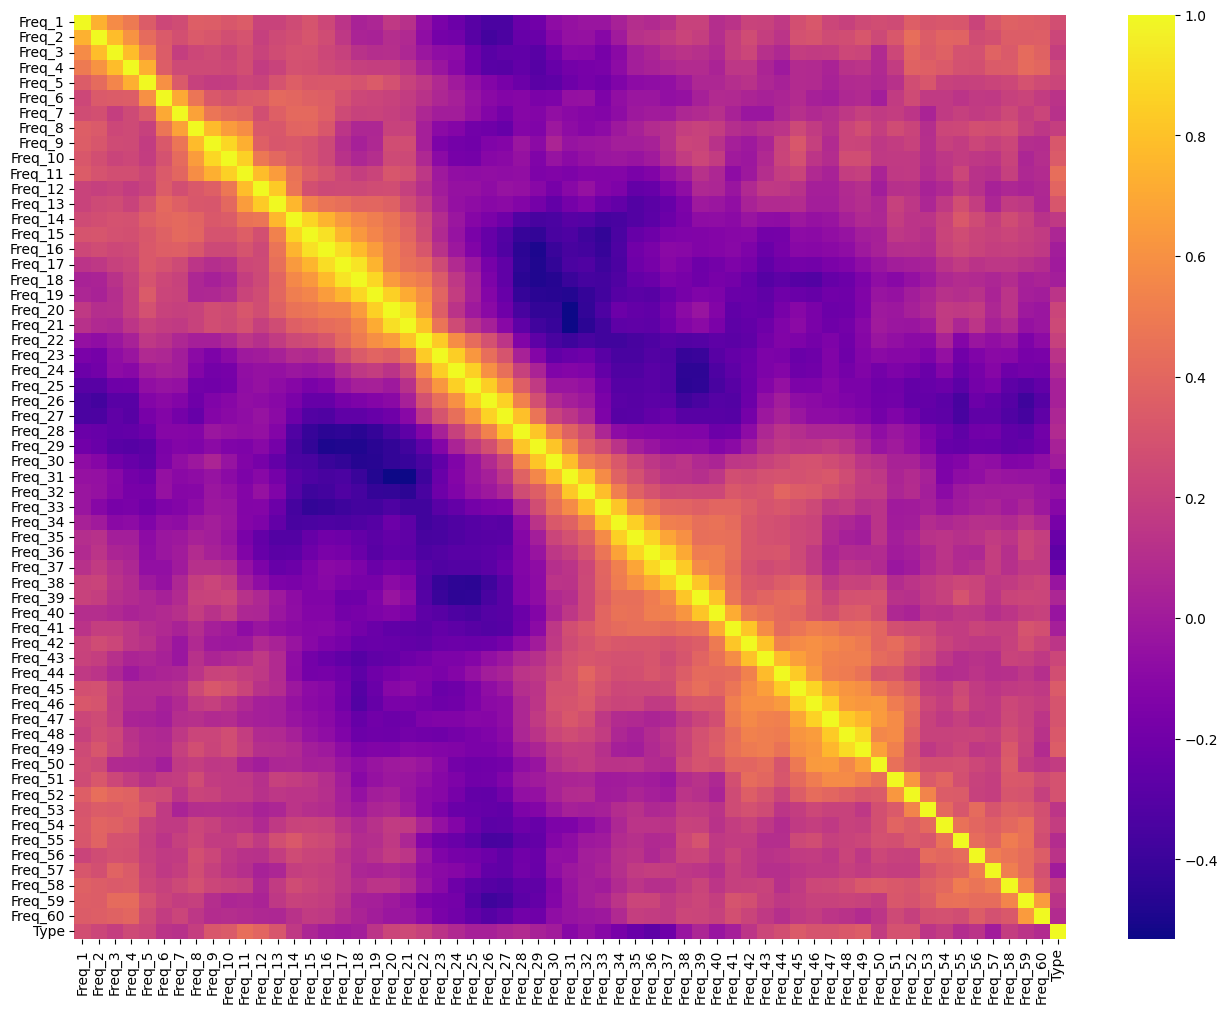

In [ ]:
plt.figure(figsize=(16,12))
sns.heatmap(df.corr(numeric_only=1),cmap='plasma')
plt.show()

In [ ]:
df=df.drop('Label',axis=1)

In [ ]:
df['Type'].value_counts()

,count
Type,
1,111
0,97


Train test split

In [ ]:
X=df.drop('Type',axis=1)
y=df['Type']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.15,random_state=42)

In [ ]:
from  sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model=KNeighborsClassifier()
param_grid={'n_neighbors':list(range(1,30))}

In [ ]:
from sklearn.model_selection import GridSearchCV
grid=GridSearchCV(estimator=model,param_grid=param_grid)

In [ ]:
grid.fit(X_train,y_train)

GridSearchCV(estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                         13, 14, 15, 16, 17, 18, 19, 20, 21, 22,
                                         23, 24, 25, 26, 27, 28, 29]})

In [ ]:
y_pred=grid.predict(X_test)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay,classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.92      0.92        13
           1       0.95      0.95      0.95        19

    accuracy                           0.94        32
   macro avg       0.94      0.94      0.94        32
weighted avg       0.94      0.94      0.94        32



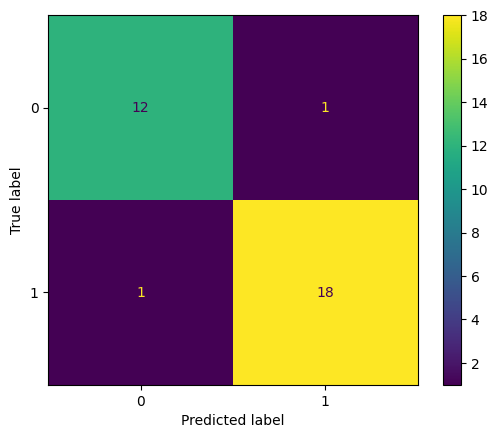

In [ ]:
ConfusionMatrixDisplay.from_estimator(grid,X_test,y_test)

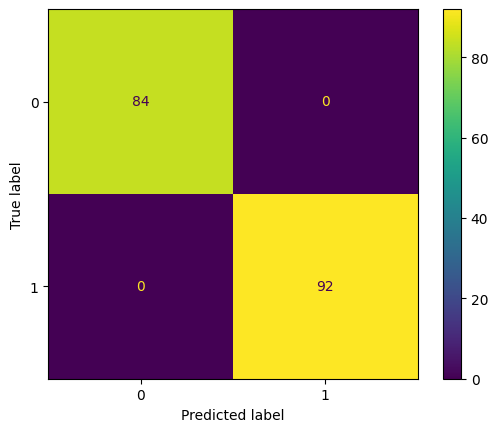

In [ ]:
ConfusionMatrixDisplay.from_estimator(grid,X_train,y_train)

In [ ]:
y_test[y_test!=y_pred]

,Type
15,0
148,1


In [ ]:
df.iloc[148]

,148
Freq_1,0.0712
Freq_2,0.0901
Freq_3,0.1276
Freq_4,0.1497
Freq_5,0.1284
...,...
Freq_57,0.0087
Freq_58,0.0101
Freq_59,0.0095
Freq_60,0.0068


In [ ]:
df[df['Type']==1].mean()

,0
Freq_1,0.034989
Freq_2,0.045544
Freq_3,0.050720
Freq_4,0.064768
Freq_5,0.086715
...,...
Freq_57,0.007825
Freq_58,0.009060
Freq_59,0.008695
Freq_60,0.006930


In [ ]:
df[df['Type']==0].mean()

,0
Freq_1,0.022498
Freq_2,0.030303
Freq_3,0.035951
Freq_4,0.041447
Freq_5,0.062028
...,...
Freq_57,0.007814
Freq_58,0.006677
Freq_59,0.007078
Freq_60,0.006024


In [ ]:
model2=KNeighborsClassifier(n_neighbors=11)
model2.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=11)

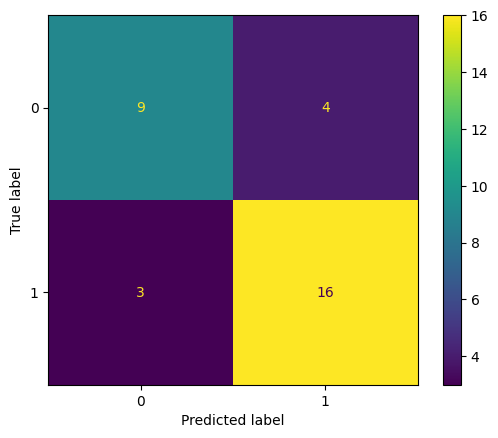

In [ ]:
ConfusionMatrixDisplay.from_estimator(model2,X_test,y_test)

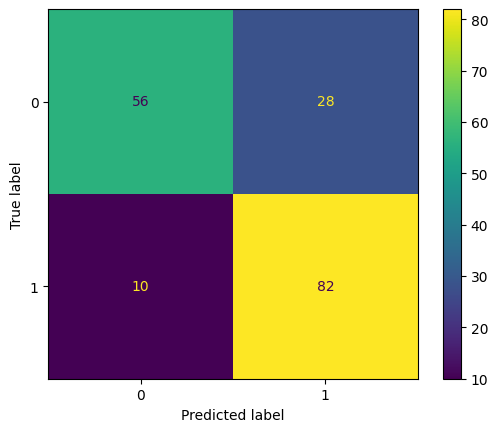

In [ ]:
ConfusionMatrixDisplay.from_estimator(model2,X_train,y_train)

In [ ]:
predict_proba=model2.predict_proba(X_test)

In [ ]:
predict_proba

array([[0.09090909, 0.90909091],
       [0.81818182, 0.18181818],
       [0.90909091, 0.09090909],
       [0.90909091, 0.09090909],
       [0.09090909, 0.90909091],
       [0.54545455, 0.45454545],
       [0.27272727, 0.72727273],
       [0.27272727, 0.72727273],
       [1.        , 0.        ],
       [0.36363636, 0.63636364],
       [0.09090909, 0.90909091],
       [0.45454545, 0.54545455],
       [0.63636364, 0.36363636],
       [0.        , 1.        ],
       [0.09090909, 0.90909091],
       [0.18181818, 0.81818182],
       [0.27272727, 0.72727273],
       [0.27272727, 0.72727273],
       [0.45454545, 0.54545455],
       [0.45454545, 0.54545455],
       [0.        , 1.        ],
       [0.54545455, 0.45454545],
       [0.18181818, 0.81818182],
       [0.36363636, 0.63636364],
       [0.72727273, 0.27272727],
       [0.90909091, 0.09090909],
       [1.        , 0.        ],
       [0.36363636, 0.63636364],
       [0.        , 1.        ],
       [0.        , 1.        ],
       [0.

In [ ]:
y_pred=(predict_proba[:,1]>0.3).astype(int)

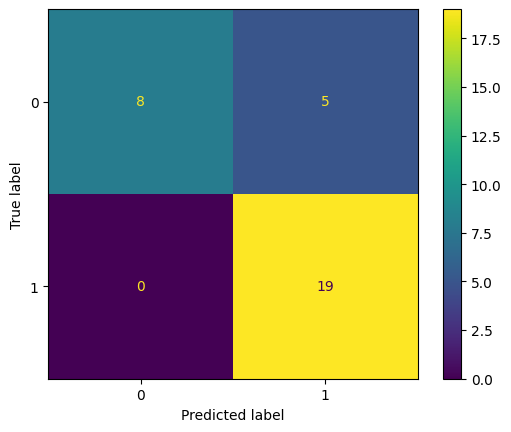

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_pred=y_pred,y_true=y_test)

In [ ]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.62      1.00      0.76         8
           1       1.00      0.79      0.88        24

    accuracy                           0.84        32
   macro avg       0.81      0.90      0.82        32
weighted avg       0.90      0.84      0.85        32



In [ ]:
y_train_proba=model2.predict_proba(X_train)

In [ ]:
train_pred=(y_train_proba[:,1]>0.3).astype(int)

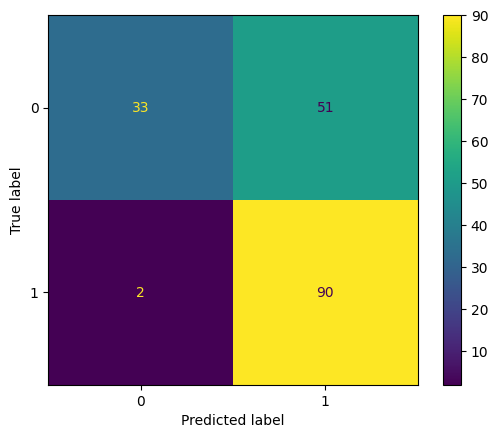

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_train,train_pred)
#train+test 2 recall loses

# Grid ile etdiyimiz model daha yaxsi idi

In [ ]:
d=np.random.random_sample((1,60))*2
d

array([[1.47169984e+00, 1.27464957e+00, 1.26190534e+00, 1.29694793e+00,
        1.63488787e-01, 5.58621399e-01, 1.06533602e+00, 1.62062016e+00,
        1.25089393e+00, 3.17137308e-01, 1.92166656e+00, 9.20353972e-01,
        1.54358715e+00, 1.37953169e+00, 1.40343943e-01, 1.80948449e+00,
        6.00344976e-01, 1.76334536e+00, 2.15038560e-02, 6.24291125e-01,
        4.76564664e-01, 1.21072525e+00, 1.31739622e+00, 1.34854732e+00,
        8.60456021e-04, 9.85599579e-01, 1.73037610e+00, 6.87364115e-01,
        1.42279160e+00, 1.31048653e+00, 7.24455995e-01, 2.80595966e-01,
        4.99883037e-01, 3.91817868e-01, 2.67017209e-01, 1.76651128e+00,
        9.83748969e-01, 1.23991998e+00, 7.58064190e-01, 1.23487729e+00,
        1.39599505e+00, 1.83461162e+00, 7.99519839e-01, 2.80195634e-01,
        3.74767738e-01, 1.72071054e+00, 1.28511974e+00, 5.38597938e-01,
        8.42938983e-01, 4.97177761e-01, 7.95801661e-02, 2.65204919e-01,
        3.07021447e-01, 7.33178207e-01, 1.74407352e+00, 1.426158

In [ ]:
grid.predict(d)

array([1])

In [ ]:
model2.predict(d)

array([1])